## 8. Порівняння сегментів користувачів (Segmentation Comparison)

In [3]:
# Імпортуємо необхідні бібліотеки

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path

In [9]:
# Знаходимо папку з обробленими даними

current_dir = Path.cwd()

possible_paths = [
    parent / "data_processed"
    for parent in [current_dir, *current_dir.parents]
]

processed_path = next(
    (path for path in possible_paths if path.is_dir()),
    None
)

if processed_path is None:
    raise FileNotFoundError(
        "Не знайдено папку data_processed"
    )


# Визначаємо назви датасетів

dataset_names = [
    "01_landing_page",
    "02_authenticated_create_room",
    "02_guest_create_room",
    "03_authenticated_host_room_invite_friends",
    "03_guest_host_room_invite_friends",
    "06_authenticated_swipe_session",
    "06_guest_swipe_session",
    "08_authenticated_results_winners",
    "08_guest_results_winners",
    "09_sign_in",
    "10_sign_up",
    "11_home_signed_in",
    "12_settings"
]


# Завантажуємо датасети

dataframes = {}

for name in dataset_names:

    file_path = processed_path / f"{name}.csv"

    if not file_path.exists():
        raise FileNotFoundError(
            f"Не знайдено файл: {file_path}"
        )

    dataframes[name] = pd.read_csv(
        file_path,
        low_memory=False
    )


# Об'єднуємо всі датасети

all_events = pd.concat(
    dataframes.values(),
    ignore_index=True
)


# Відновлюємо типи ідентифікаторів

id_columns = [
    "event_id",
    "page_view_id",
    "visitor_id",
    "user_id",
    "room_id",
    "participant_id",
    "room_title_id",
    "title_id",
    "archive_session_id"
]

for column in id_columns:

    if column in all_events.columns:
        all_events[column] = all_events[column].astype("string")


# Перетворюємо часові значення

if "event_timestamp" in all_events.columns:

    all_events["event_timestamp"] = pd.to_datetime(
        all_events["event_timestamp"],
        errors="coerce",
        utc=True
    )


# Перетворюємо числові колонки

numeric_columns = [
    "card_position",
    "vote_average",
    "release_year",
    "runtime_minutes"
]

for column in numeric_columns:

    if column in all_events.columns:

        all_events[column] = pd.to_numeric(
            all_events[column],
            errors="coerce"
        )


# Відновлюємо Boolean-значення

if "event_value_bool" in all_events.columns:

    bool_values = all_events["event_value_bool"].astype("object")

else:

    bool_values = pd.Series(
        pd.NA,
        index=all_events.index,
        dtype="object"
    )


# Заповнюємо пропущені значення з event_value

if "event_value" in all_events.columns:

    event_values = all_events["event_value"].astype("object")

    bool_values = bool_values.where(
        pd.notna(bool_values),
        event_values
    )


# Перетворюємо значення на Boolean

all_events["event_value_bool"] = (
    bool_values
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "false": False
    })
    .astype("boolean")
)


# Перевіряємо наявність колонки event_value_type

if "event_value_type" not in all_events.columns:

    raise ValueError(
        "У датасетах відсутня колонка event_value_type"
    )


# Відокремлюємо фактичні події

# Boolean-події залишаємо лише зі значенням True.
# Інші типи подій залишаємо без додаткової фільтрації.

is_boolean = (
    all_events["event_value_type"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("boolean")
)

is_true = (
    all_events["event_value_bool"]
    .eq(True)
    .fillna(False)
)

activity_df = all_events.loc[
    (~is_boolean) | is_true
].copy()


# Виводимо загальну інформацію

print("\nПапка з даними:", processed_path)

print(
    "Кількість датасетів:",
    len(dataframes)
)

print(
    "Загальна кількість записів:",
    f"{len(all_events):,}"
)

print(
    "Кількість фактичних подій:",
    f"{len(activity_df):,}"
)

print(
    "Кількість Boolean-подій:",
    f"{is_boolean.sum():,}"
)

print(
    "Кількість виключених Boolean-подій:",
    f"{(is_boolean & ~is_true).sum():,}"
)


# Виводимо кількість записів у кожному датасеті

print("\nЗавантажені датасети:")

for name, df in dataframes.items():

    print(
        f"{name}: {len(df):,} записів"
    )


Папка з даними: c:\Users\ACER\github\analytics\test_analytics\data_processed
Кількість датасетів: 13
Загальна кількість записів: 69,431
Кількість фактичних подій: 47,657
Кількість Boolean-подій: 27,875
Кількість виключених Boolean-подій: 21,774

Завантажені датасети:
01_landing_page: 15,000 записів
02_authenticated_create_room: 900 записів
02_guest_create_room: 1,375 записів
03_authenticated_host_room_invite_friends: 900 записів
03_guest_host_room_invite_friends: 1,100 записів
06_authenticated_swipe_session: 16,170 записів
06_guest_swipe_session: 21,230 записів
08_authenticated_results_winners: 3,813 записів
08_guest_results_winners: 3,903 записів
09_sign_in: 960 записів
10_sign_up: 636 записів
11_home_signed_in: 3,012 записів
12_settings: 432 записів


In [10]:
# Визначаємо позитивні та негативні події голосування

vote_mapping = {
    "swipe_right": True,
    "Like_button": True,
    "movie_liked": True,
    "swipe_left": False,
    "dislike_button": False,
    "movie_disliked": False
}


# Відбираємо події голосування

vote_df = activity_df.loc[
    activity_df["event_name"].isin(vote_mapping.keys())
].copy()

if vote_df.empty:
    raise ValueError("Не знайдено подій голосування")


# Перевіряємо наявність необхідних колонок

required_columns = [
    "event_id",
    "event_name",
    "room_id",
    "participant_id",
    "user_type",
    "title_id"
]

missing_columns = [
    column
    for column in required_columns
    if column not in vote_df.columns
]

if missing_columns:
    raise ValueError(
        f"Відсутні необхідні колонки: {missing_columns}"
    )


# Додаємо необов'язкові колонки для подальшого аналізу

optional_columns = [
    "vote_average",
    "genres_json",
    "room_title_id"
]

for column in optional_columns:
    if column not in vote_df.columns:
        vote_df[column] = pd.NA


# Визначаємо тип голосу

vote_df["is_liked"] = (
    vote_df["event_name"]
    .map(vote_mapping)
    .astype(bool)
)


# Видаляємо записи без ключових ідентифікаторів

initial_vote_count = len(vote_df)

vote_df = vote_df.dropna(
    subset=[
        "event_id",
        "room_id",
        "participant_id",
        "user_type",
        "title_id"
    ]
).copy()

removed_vote_records = initial_vote_count - len(vote_df)


# Стандартизуємо тип користувача

vote_df["user_type"] = (
    vote_df["user_type"]
    .astype("string")
    .str.strip()
    .str.upper()
)


# Перетворюємо рейтинг фільму на числовий тип

vote_df["vote_average"] = pd.to_numeric(
    vote_df["vote_average"],
    errors="coerce"
)


# Перевіряємо дублювання голосів

if vote_df["room_title_id"].notna().all():
    vote_key_column = "room_title_id"
else:
    vote_key_column = "title_id"

duplicate_mask = vote_df.duplicated(
    subset=[
        "room_id",
        "participant_id",
        vote_key_column
    ],
    keep=False
)

duplicate_records = int(duplicate_mask.sum())

if duplicate_records > 0:
    raise ValueError(
        f"Виявлено {duplicate_records} записів, "
        "залучених до дублювання голосів"
    )


# Перевіряємо унікальність event_id

if vote_df["event_id"].duplicated().any():
    raise ValueError(
        "Виявлено повторні event_id у таблиці голосування"
    )


# Формуємо таблицю перевірки якості голосування

vote_quality_summary = pd.DataFrame({
    "check": [
        "Total vote records before cleaning",
        "Records with missing identifiers",
        "Records involved in duplicate vote keys",
        "Valid vote records"
    ],
    "result": [
        initial_vote_count,
        removed_vote_records,
        duplicate_records,
        len(vote_df)
    ]
})

display(vote_quality_summary)


# Розраховуємо кількість позитивних та негативних голосів

vote_type_summary = (
    vote_df.assign(
        vote_type=np.where(
            vote_df["is_liked"],
            "LIKE",
            "DISLIKE"
        )
    )
    .groupby("vote_type")
    .size()
    .reset_index(name="total_votes")
)

vote_type_summary["share_pct"] = (
    vote_type_summary["total_votes"] /
    vote_type_summary["total_votes"].sum() * 100
)

display(vote_type_summary.round(2))

,check,result
0,Total vote records before cleaning,34000
1,Records with missing identifiers,0
2,Records involved in duplicate vote keys,0
3,Valid vote records,34000


,vote_type,total_votes,share_pct
0,DISLIKE,15494,45.57
1,LIKE,18506,54.43


In [11]:
# Визначаємо сесію учасника за room_id та participant_id

session_keys = [
    "room_id",
    "participant_id"
]


# Перевіряємо узгодженість типу користувача в межах сесії

user_type_consistency = (
    vote_df.groupby(session_keys)["user_type"]
    .nunique()
)

if (user_type_consistency > 1).any():
    raise ValueError(
        "В одній сесії учасника знайдено декілька типів користувачів"
    )


# Розділяємо рейтинги фільмів за типом голосу

vote_df["liked_movie_rating"] = vote_df["vote_average"].where(
    vote_df["is_liked"]
)

vote_df["disliked_movie_rating"] = vote_df["vote_average"].where(
    ~vote_df["is_liked"]
)


# Розраховуємо показники на рівні сесії учасника

session_summary = (
    vote_df.groupby(
        session_keys,
        as_index=False
    )
    .agg(
        user_type=("user_type", "first"),
        total_votes=("event_id", "count"),
        likes=("is_liked", "sum"),
        unique_movies=("title_id", "nunique"),
        avg_movie_rating=("vote_average", "mean"),
        avg_rating_liked=("liked_movie_rating", "mean"),
        avg_rating_disliked=("disliked_movie_rating", "mean")
    )
)


# Розраховуємо кількість негативних голосів

session_summary["dislikes"] = (
    session_summary["total_votes"] -
    session_summary["likes"]
)


# Розраховуємо частки позитивних і негативних голосів

session_summary["like_rate_pct"] = (
    session_summary["likes"] /
    session_summary["total_votes"] * 100
)

session_summary["dislike_rate_pct"] = (
    session_summary["dislikes"] /
    session_summary["total_votes"] * 100
)


# Визначаємо поведінковий сегмент

def define_voting_segment(like_rate):

    if pd.isna(like_rate):
        return pd.NA

    if like_rate >= 65:
        return "Переважно позитивні"

    elif like_rate < 45:
        return "Переважно негативні"

    else:
        return "Збалансовані"


# Задаємо порядок сегментів

segment_order = [
    "Переважно позитивні",
    "Збалансовані",
    "Переважно негативні"
]


# Присвоюємо кожній сесії відповідний сегмент

session_summary["behavior_segment"] = (
    session_summary["like_rate_pct"]
    .apply(define_voting_segment)
)

session_summary["behavior_segment"] = pd.Categorical(
    session_summary["behavior_segment"],
    categories=segment_order,
    ordered=True
)


# Переглядаємо результати сегментації

display(session_summary.head(10))

print("Кількість сесій:", len(session_summary))

print(
    "Кількість унікальних учасників:",
    session_summary["participant_id"].nunique()
)

print("\nРозподіл сегментів:")

display(
    session_summary["behavior_segment"]
    .value_counts(sort=False)
    .rename_axis("behavior_segment")
    .reset_index(name="participant_sessions")
)

,room_id,participant_id,user_type,total_votes,likes,unique_movies,avg_movie_rating,avg_rating_liked,avg_rating_disliked,dislikes,like_rate_pct,dislike_rate_pct,behavior_segment
0,500001.0,700001.0,AUTHENTICATED,20,7,20,7.081,7.282857,6.972308,13,35.0,65.0,Переважно негативні
1,500001.0,700002.0,GUEST,20,11,20,7.081,7.441818,6.640000,9,55.0,45.0,Збалансовані
2,500001.0,700003.0,GUEST,20,12,20,7.081,6.726667,7.612500,8,60.0,40.0,Збалансовані
3,500001.0,700004.0,GUEST,20,9,20,7.081,7.100000,7.065455,11,45.0,55.0,Збалансовані
4,500001.0,700005.0,GUEST,20,8,20,7.081,6.176250,7.684167,12,40.0,60.0,Переважно негативні
5,500002.0,700006.0,GUEST,20,12,20,6.125,6.369167,5.758750,8,60.0,40.0,Збалансовані
6,500002.0,700007.0,AUTHENTICATED,20,10,20,6.125,6.015000,6.235000,10,50.0,50.0,Збалансовані
7,500002.0,700008.0,GUEST,20,11,20,6.125,6.350000,5.850000,9,55.0,45.0,Збалансовані
8,500002.0,700009.0,AUTHENTICATED,20,11,20,6.125,5.797273,6.525556,9,55.0,45.0,Збалансовані
9,500002.0,700010.0,GUEST,20,10,20,6.125,6.343000,5.907000,10,50.0,50.0,Збалансовані


Кількість сесій: 1700
Кількість унікальних учасників: 1700

Розподіл сегментів:


,behavior_segment,participant_sessions
0,Переважно позитивні,429
1,Збалансовані,1010
2,Переважно негативні,261


In [12]:
# Визначаємо сесію учасника за room_id та participant_id

session_keys = [
    "room_id",
    "participant_id"
]


# Перевіряємо узгодженість типу користувача в межах сесії

user_type_consistency = (
    vote_df.groupby(session_keys)["user_type"]
    .nunique()
)

if (user_type_consistency > 1).any():
    raise ValueError(
        "В одній сесії учасника знайдено декілька типів користувачів"
    )


# Розділяємо рейтинги фільмів за типом голосу

vote_df["liked_movie_rating"] = vote_df["vote_average"].where(
    vote_df["is_liked"]
)

vote_df["disliked_movie_rating"] = vote_df["vote_average"].where(
    ~vote_df["is_liked"]
)


# Розраховуємо показники на рівні сесії учасника

session_summary = (
    vote_df.groupby(
        session_keys,
        as_index=False
    )
    .agg(
        user_type=("user_type", "first"),
        total_votes=("event_id", "count"),
        likes=("is_liked", "sum"),
        unique_movies=("title_id", "nunique"),
        avg_movie_rating=("vote_average", "mean"),
        avg_rating_liked=("liked_movie_rating", "mean"),
        avg_rating_disliked=("disliked_movie_rating", "mean")
    )
)


# Розраховуємо кількість негативних голосів

session_summary["dislikes"] = (
    session_summary["total_votes"] -
    session_summary["likes"]
)


# Розраховуємо частки позитивних і негативних голосів

session_summary["like_rate_pct"] = (
    session_summary["likes"] /
    session_summary["total_votes"] * 100
)

session_summary["dislike_rate_pct"] = (
    session_summary["dislikes"] /
    session_summary["total_votes"] * 100
)


# Визначаємо поведінковий сегмент

def define_voting_segment(like_rate):

    if pd.isna(like_rate):
        return pd.NA

    if like_rate >= 65:
        return "Переважно позитивні"

    elif like_rate < 45:
        return "Переважно негативні"

    else:
        return "Збалансовані"


# Задаємо порядок сегментів

segment_order = [
    "Переважно позитивні",
    "Збалансовані",
    "Переважно негативні"
]


# Присвоюємо кожній сесії відповідний сегмент

session_summary["behavior_segment"] = (
    session_summary["like_rate_pct"]
    .apply(define_voting_segment)
)

session_summary["behavior_segment"] = pd.Categorical(
    session_summary["behavior_segment"],
    categories=segment_order,
    ordered=True
)


# Переглядаємо результати сегментації

display(session_summary.head(10))

print("Кількість сесій:", len(session_summary))

print(
    "Кількість унікальних учасників:",
    session_summary["participant_id"].nunique()
)

print("\nРозподіл сегментів:")

display(
    session_summary["behavior_segment"]
    .value_counts(sort=False)
    .rename_axis("behavior_segment")
    .reset_index(name="participant_sessions")
)

,room_id,participant_id,user_type,total_votes,likes,unique_movies,avg_movie_rating,avg_rating_liked,avg_rating_disliked,dislikes,like_rate_pct,dislike_rate_pct,behavior_segment
0,500001.0,700001.0,AUTHENTICATED,20,7,20,7.081,7.282857,6.972308,13,35.0,65.0,Переважно негативні
1,500001.0,700002.0,GUEST,20,11,20,7.081,7.441818,6.640000,9,55.0,45.0,Збалансовані
2,500001.0,700003.0,GUEST,20,12,20,7.081,6.726667,7.612500,8,60.0,40.0,Збалансовані
3,500001.0,700004.0,GUEST,20,9,20,7.081,7.100000,7.065455,11,45.0,55.0,Збалансовані
4,500001.0,700005.0,GUEST,20,8,20,7.081,6.176250,7.684167,12,40.0,60.0,Переважно негативні
5,500002.0,700006.0,GUEST,20,12,20,6.125,6.369167,5.758750,8,60.0,40.0,Збалансовані
6,500002.0,700007.0,AUTHENTICATED,20,10,20,6.125,6.015000,6.235000,10,50.0,50.0,Збалансовані
7,500002.0,700008.0,GUEST,20,11,20,6.125,6.350000,5.850000,9,55.0,45.0,Збалансовані
8,500002.0,700009.0,AUTHENTICATED,20,11,20,6.125,5.797273,6.525556,9,55.0,45.0,Збалансовані
9,500002.0,700010.0,GUEST,20,10,20,6.125,6.343000,5.907000,10,50.0,50.0,Збалансовані


Кількість сесій: 1700
Кількість унікальних учасників: 1700

Розподіл сегментів:


,behavior_segment,participant_sessions
0,Переважно позитивні,429
1,Збалансовані,1010
2,Переважно негативні,261


,behavior_segment,participant_sessions,total_votes,avg_like_rate,median_like_rate,avg_likes,avg_dislikes,share_pct
0,Переважно позитивні,429,8580,69.73,70.0,13.95,6.05,25.24
1,Збалансовані,1010,20200,52.82,55.0,10.56,9.44,59.41
2,Переважно негативні,261,5220,35.50,40.0,7.10,12.90,15.35


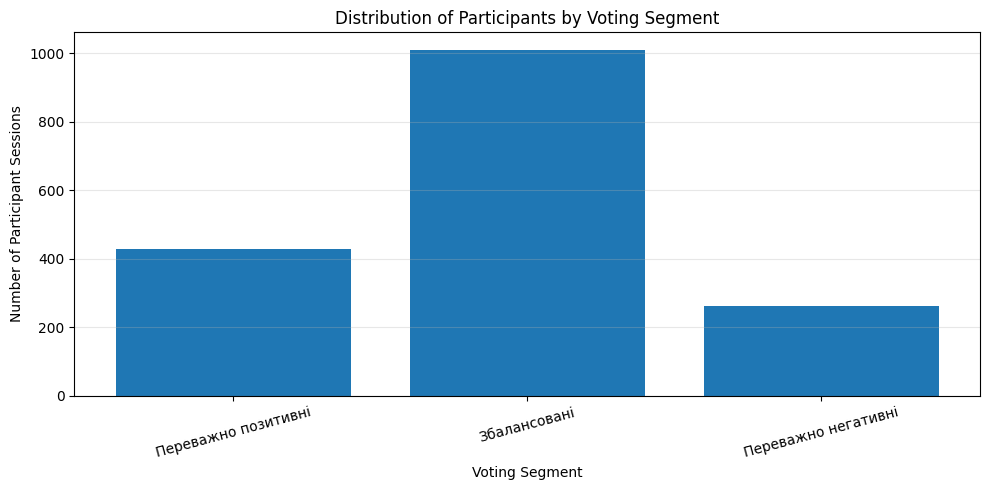

In [13]:
# Розраховуємо кількість сесій та показники кожного сегмента

segment_distribution = (
    session_summary.groupby(
        "behavior_segment",
        observed=False
    )
    .agg(
        participant_sessions=("participant_id", "count"),
        total_votes=("total_votes", "sum"),
        avg_like_rate=("like_rate_pct", "mean"),
        median_like_rate=("like_rate_pct", "median"),
        avg_likes=("likes", "mean"),
        avg_dislikes=("dislikes", "mean")
    )
    .reindex(segment_order)
    .reset_index()
)


# Розраховуємо частку кожного сегмента

total_sessions = len(session_summary)

segment_distribution["share_pct"] = (
    segment_distribution["participant_sessions"] /
    total_sessions * 100
)


# Виводимо таблицю розподілу сегментів

display(segment_distribution.round(2))


# Візуалізуємо розподіл учасників

plt.figure(figsize=(10, 5))

plt.bar(
    segment_distribution["behavior_segment"].astype(str),
    segment_distribution["participant_sessions"]
)

plt.title("Distribution of Participants by Voting Segment")
plt.xlabel("Voting Segment")
plt.ylabel("Number of Participant Sessions")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

,user_type,behavior_segment,participant_sessions,avg_like_rate,share_pct
0,AUTHENTICATED,Переважно позитивні,202,69.53,27.48
1,AUTHENTICATED,Збалансовані,407,52.70,55.37
2,AUTHENTICATED,Переважно негативні,126,35.56,17.14
3,GUEST,Переважно позитивні,227,69.91,23.52
4,GUEST,Збалансовані,603,52.90,62.49
5,GUEST,Переважно негативні,135,35.44,13.99


behavior_segment,Переважно позитивні,Збалансовані,Переважно негативні
user_type,,,
AUTHENTICATED,27.48,55.37,17.14
GUEST,23.52,62.49,13.99


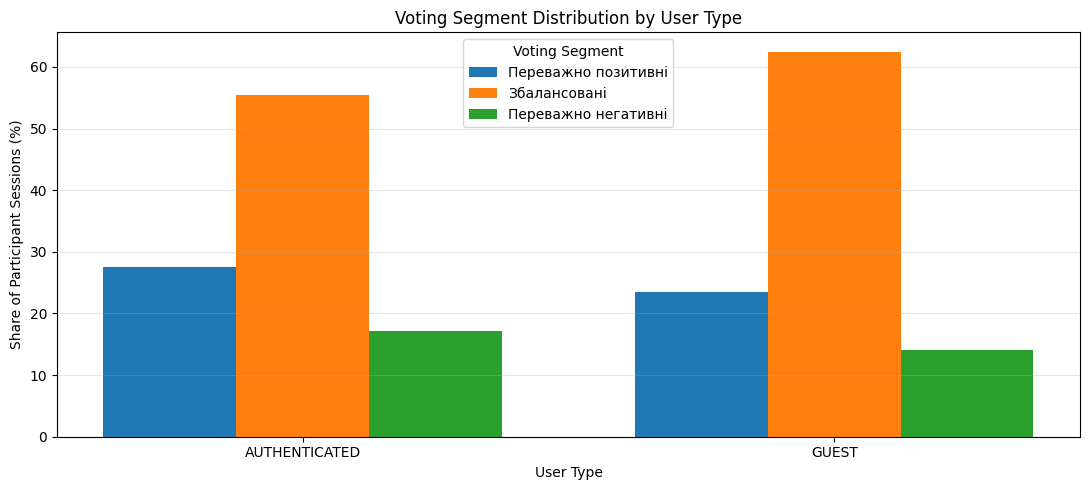

In [14]:
# Порівнюємо кількість сесій у кожному сегменті за типом користувача

segment_by_user_type = (
    session_summary.groupby(
        ["user_type", "behavior_segment"],
        observed=True
    )
    .agg(
        participant_sessions=("participant_id", "count"),
        avg_like_rate=("like_rate_pct", "mean")
    )
    .reset_index()
)


# Розраховуємо частку сегментів у межах кожної групи користувачів

segment_by_user_type["share_pct"] = (
    segment_by_user_type["participant_sessions"] /
    segment_by_user_type.groupby("user_type")[
        "participant_sessions"
    ].transform("sum") * 100
)


# Виводимо результати порівняння

display(segment_by_user_type.round(2))


# Формуємо порівняльну таблицю

segment_comparison_pivot = (
    segment_by_user_type.pivot(
        index="user_type",
        columns="behavior_segment",
        values="share_pct"
    )
    .reindex(columns=segment_order)
    .fillna(0)
)

display(segment_comparison_pivot.round(2))


# Візуалізуємо розподіл сегментів за типом користувача

plt.figure(figsize=(11, 5))

user_types = segment_comparison_pivot.index.tolist()
x = np.arange(len(user_types))
width = 0.25

for i, segment in enumerate(segment_order):

    offset = (i - 1) * width

    plt.bar(
        x + offset,
        segment_comparison_pivot[segment].values,
        width,
        label=segment
    )

plt.title("Voting Segment Distribution by User Type")
plt.xlabel("User Type")
plt.ylabel("Share of Participant Sessions (%)")

plt.xticks(x, user_types)
plt.legend(title="Voting Segment")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# Створюємо функцію для отримання жанрів із JSON

def parse_genres(value):

    if isinstance(value, (list, tuple)):
        return list(value)

    if value is None or pd.isna(value):
        return []

    try:
        parsed = json.loads(str(value))

        if isinstance(parsed, list):
            return parsed

        return []

    except (json.JSONDecodeError, TypeError):
        return []


# Відбираємо дані голосування з інформацією про жанри

genre_data = vote_df[
    [
        "event_id",
        "room_id",
        "participant_id",
        "genres_json",
        "is_liked"
    ]
].copy()


# Розпаковуємо список жанрів

genre_data["genre"] = genre_data["genres_json"].apply(parse_genres)

genre_data = genre_data.explode("genre")

genre_data["genre"] = (
    genre_data["genre"]
    .astype("string")
    .str.strip()
)

genre_data = genre_data.dropna(
    subset=["genre"]
).copy()

genre_data = genre_data.loc[
    genre_data["genre"] != ""
].copy()


# Видаляємо повтори жанрів для одного голосу

genre_data = genre_data.drop_duplicates(
    subset=["event_id", "genre"]
)


# Додаємо сегмент учасника до голосування

genre_data = genre_data.merge(
    session_summary[
        [
            "room_id",
            "participant_id",
            "behavior_segment"
        ]
    ],
    on=["room_id", "participant_id"],
    how="left",
    validate="many_to_one"
)


# Розраховуємо кількість унікальних жанрів у кожній сесії

session_genre_diversity = (
    genre_data.groupby(session_keys)["genre"]
    .nunique()
    .reset_index(name="unique_genres")
)


# Додаємо жанрову різноманітність до таблиці сесій

session_summary = session_summary.merge(
    session_genre_diversity,
    on=session_keys,
    how="left",
    validate="one_to_one"
)

session_summary["unique_genres"] = (
    session_summary["unique_genres"].fillna(0)
)


# Розраховуємо показники голосування за жанрами та сегментами

genre_segment_summary = (
    genre_data.groupby(
        ["behavior_segment", "genre"],
        observed=True
    )
    .agg(
        total_votes=("event_id", "count"),
        likes=("is_liked", "sum")
    )
    .reset_index()
)

genre_segment_summary["dislikes"] = (
    genre_segment_summary["total_votes"] -
    genre_segment_summary["likes"]
)

genre_segment_summary["like_rate_pct"] = (
    genre_segment_summary["likes"] /
    genre_segment_summary["total_votes"] * 100
)


# Визначаємо п'ять жанрів із найбільшою часткою позитивних голосів

top_genres_by_segment = (
    genre_segment_summary
    .sort_values(
        ["behavior_segment", "like_rate_pct"],
        ascending=[True, False]
    )
    .groupby(
        "behavior_segment",
        observed=True
    )
    .head(5)
)


# Формуємо порівняльну таблицю жанрових уподобань

genre_segment_pivot = genre_segment_summary.pivot(
    index="genre",
    columns="behavior_segment",
    values="like_rate_pct"
).reindex(columns=segment_order)


# Виводимо результати жанрового аналізу

print("Кількість записів із жанровою інформацією:", len(genre_data))

print("\nЖанрові показники за сегментами:")

display(genre_segment_summary.round(2))

print("\nТоп-5 жанрів за часткою позитивних голосів:")

display(top_genres_by_segment.round(2))

print("\nПорівняння частки позитивних голосів за жанрами:")

display(genre_segment_pivot.round(2))

Кількість записів із жанровою інформацією: 73387

Жанрові показники за сегментами:


,behavior_segment,genre,total_votes,likes,dislikes,like_rate_pct
0,Переважно позитивні,Action,1002,696,306,69.46
1,Переважно позитивні,Adventure,1037,724,313,69.82
2,Переважно позитивні,Animation,1107,781,326,70.55
3,Переважно позитивні,Comedy,1057,728,329,68.87
4,Переважно позитивні,Crime,949,667,282,70.28
5,Переважно позитивні,Documentary,1053,754,299,71.60
6,Переважно позитивні,Drama,1064,721,343,67.76
7,Переважно позитивні,Family,945,680,265,71.96
8,Переважно позитивні,Fantasy,954,682,272,71.49
9,Переважно позитивні,History,1070,745,325,69.63



Топ-5 жанрів за часткою позитивних голосів:


,behavior_segment,genre,total_votes,likes,dislikes,like_rate_pct
11,Переважно позитивні,Music,1060,767,293,72.36
7,Переважно позитивні,Family,945,680,265,71.96
5,Переважно позитивні,Documentary,1053,754,299,71.60
17,Переважно позитивні,Western,1091,781,310,71.59
8,Переважно позитивні,Fantasy,954,682,272,71.49
26,Збалансовані,Fantasy,2027,1119,908,55.20
25,Збалансовані,Family,2380,1311,1069,55.08
34,Збалансовані,War,2405,1318,1087,54.80
19,Збалансовані,Adventure,2389,1292,1097,54.08
29,Збалансовані,Music,2650,1431,1219,54.00



Порівняння частки позитивних голосів за жанрами:


behavior_segment,Переважно позитивні,Збалансовані,Переважно негативні
genre,,,
Action,69.46,53.92,36.07
Adventure,69.82,54.08,33.22
Animation,70.55,53.75,38.73
Comedy,68.87,53.02,34.89
Crime,70.28,53.24,37.62
Documentary,71.60,52.94,35.79
Drama,67.76,53.75,35.81
Family,71.96,55.08,34.43
Fantasy,71.49,55.20,34.13


In [16]:
# Розраховуємо середні показники для кожного сегмента

segment_profile = (
    session_summary.groupby(
        "behavior_segment",
        observed=False
    )
    .agg(
        participant_sessions=("participant_id", "count"),
        avg_votes=("total_votes", "mean"),
        avg_likes=("likes", "mean"),
        avg_dislikes=("dislikes", "mean"),
        avg_like_rate_pct=("like_rate_pct", "mean"),
        median_like_rate_pct=("like_rate_pct", "median"),
        avg_unique_movies=("unique_movies", "mean"),
        avg_unique_genres=("unique_genres", "mean"),
        avg_rating_liked=("avg_rating_liked", "mean"),
        avg_rating_disliked=("avg_rating_disliked", "mean")
    )
    .reindex(segment_order)
    .reset_index()
)


# Виводимо профілі поведінкових сегментів

display(segment_profile.round(2))


# Порівнюємо середню кількість позитивних та негативних голосів

likes_dislikes_comparison = segment_profile[
    [
        "behavior_segment",
        "avg_likes",
        "avg_dislikes"
    ]
].copy()

display(likes_dislikes_comparison.round(2))


# Порівнюємо середні рейтинги фільмів

rating_comparison = segment_profile[
    [
        "behavior_segment",
        "avg_rating_liked",
        "avg_rating_disliked"
    ]
].copy()

display(rating_comparison.round(2))

,behavior_segment,participant_sessions,avg_votes,avg_likes,avg_dislikes,avg_like_rate_pct,median_like_rate_pct,avg_unique_movies,avg_unique_genres,avg_rating_liked,avg_rating_disliked
0,Переважно позитивні,429,20.0,13.95,6.05,69.73,70.0,20.0,14.80,7.01,7.02
1,Збалансовані,1010,20.0,10.56,9.44,52.82,55.0,20.0,14.75,6.95,6.99
2,Переважно негативні,261,20.0,7.10,12.90,35.50,40.0,20.0,14.77,7.02,6.97


,behavior_segment,avg_likes,avg_dislikes
0,Переважно позитивні,13.95,6.05
1,Збалансовані,10.56,9.44
2,Переважно негативні,7.10,12.90


,behavior_segment,avg_rating_liked,avg_rating_disliked
0,Переважно позитивні,7.01,7.02
1,Збалансовані,6.95,6.99
2,Переважно негативні,7.02,6.97


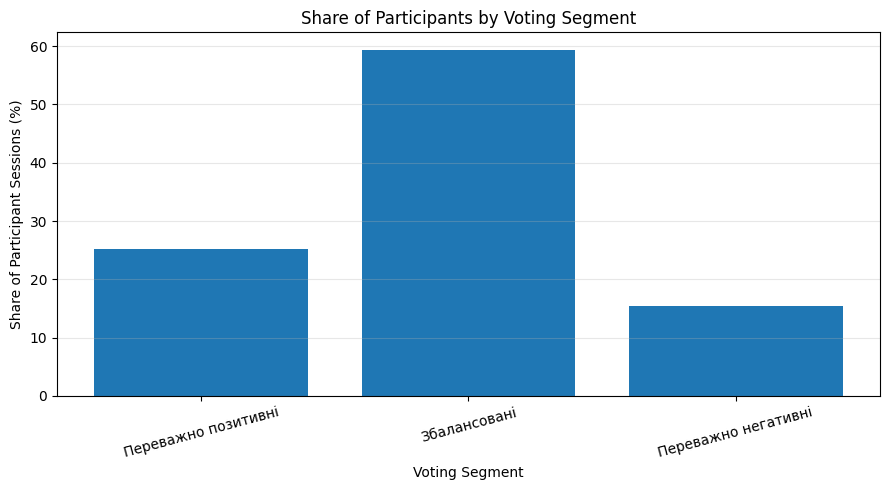

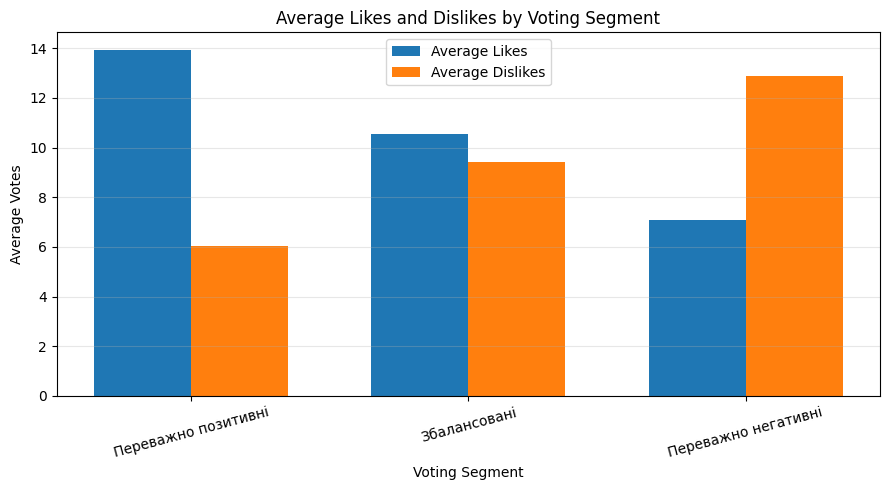

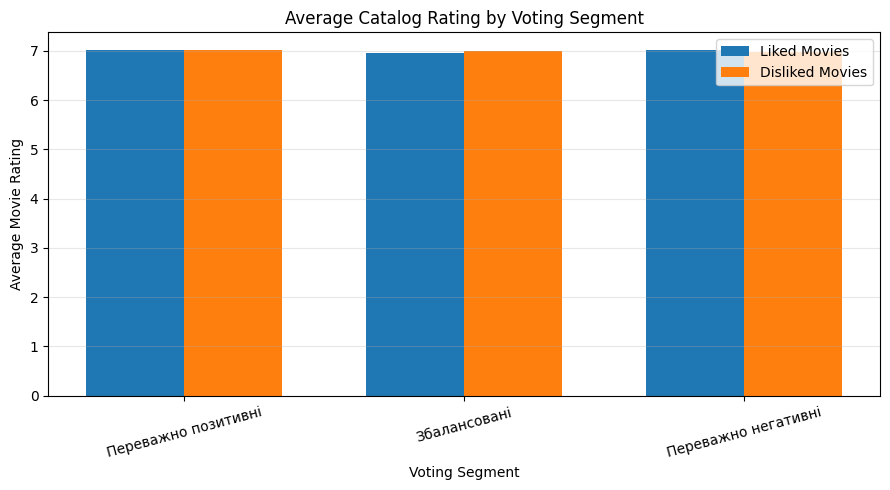

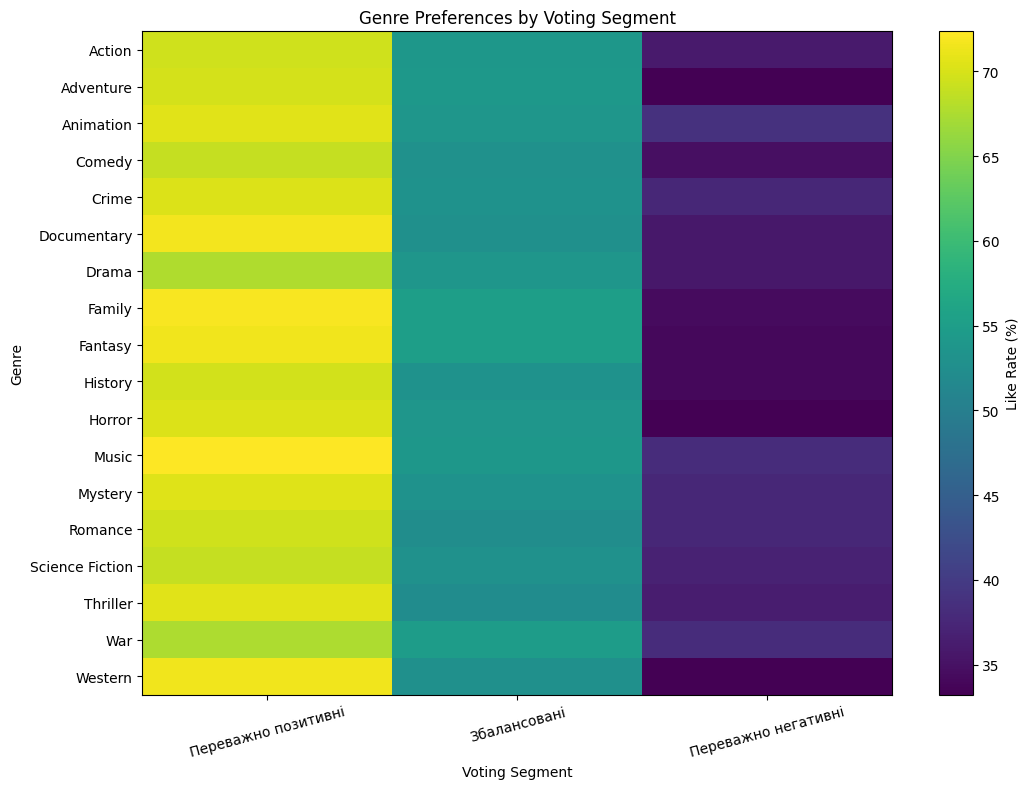

In [17]:
# Візуалізуємо частку кожного поведінкового сегмента

plt.figure(figsize=(9, 5))

plt.bar(
    segment_distribution["behavior_segment"].astype(str),
    segment_distribution["share_pct"]
)

plt.title("Share of Participants by Voting Segment")
plt.xlabel("Voting Segment")
plt.ylabel("Share of Participant Sessions (%)")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Порівнюємо середню кількість Likes та Dislikes

x = np.arange(len(segment_profile))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    segment_profile["avg_likes"],
    width,
    label="Average Likes"
)

plt.bar(
    x + width / 2,
    segment_profile["avg_dislikes"],
    width,
    label="Average Dislikes"
)

plt.title("Average Likes and Dislikes by Voting Segment")
plt.xlabel("Voting Segment")
plt.ylabel("Average Votes")

plt.xticks(
    x,
    segment_profile["behavior_segment"].astype(str),
    rotation=15
)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Порівнюємо середні рейтинги фільмів за типом голосу

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    segment_profile["avg_rating_liked"],
    width,
    label="Liked Movies"
)

plt.bar(
    x + width / 2,
    segment_profile["avg_rating_disliked"],
    width,
    label="Disliked Movies"
)

plt.title("Average Catalog Rating by Voting Segment")
plt.xlabel("Voting Segment")
plt.ylabel("Average Movie Rating")

plt.xticks(
    x,
    segment_profile["behavior_segment"].astype(str),
    rotation=15
)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Візуалізуємо жанрові вподобання за допомогою теплової карти

if not genre_segment_pivot.empty:

    plt.figure(figsize=(11, 8))

    plt.imshow(
        genre_segment_pivot.astype(float),
        aspect="auto"
    )

    plt.colorbar(label="Like Rate (%)")

    plt.title("Genre Preferences by Voting Segment")
    plt.xlabel("Voting Segment")
    plt.ylabel("Genre")

    plt.xticks(
        range(len(genre_segment_pivot.columns)),
        genre_segment_pivot.columns.astype(str),
        rotation=15
    )

    plt.yticks(
        range(len(genre_segment_pivot.index)),
        genre_segment_pivot.index
    )

    plt.tight_layout()
    plt.show()

else:

    print("Відсутні жанрові дані для побудови теплової карти.")

In [18]:
# Формуємо загальну таблицю результатів сегментації

segmentation_summary = pd.DataFrame({
    "metric": [
        "Total participant sessions",
        "Positive-oriented sessions",
        "Balanced sessions",
        "Negative-oriented sessions",
        "Average Like Rate",
        "Average votes per session",
        "Average unique movies per session",
        "Average unique genres per session"
    ],
    "value": [
        len(session_summary),

        (
            session_summary["behavior_segment"] ==
            "Переважно позитивні"
        ).sum(),

        (
            session_summary["behavior_segment"] ==
            "Збалансовані"
        ).sum(),

        (
            session_summary["behavior_segment"] ==
            "Переважно негативні"
        ).sum(),

        session_summary["like_rate_pct"].mean(),

        session_summary["total_votes"].mean(),

        session_summary["unique_movies"].mean(),

        session_summary["unique_genres"].mean()
    ]
})


# Перевіряємо повноту голосування

session_vote_completeness = (
    session_summary.groupby("user_type")
    .agg(
        total_sessions=("total_votes", "count"),
        sessions_with_20_votes=(
            "total_votes",
            lambda x: (x == 20).sum()
        ),
        sessions_with_less_than_20=(
            "total_votes",
            lambda x: (x < 20).sum()
        ),
        sessions_with_more_than_20=(
            "total_votes",
            lambda x: (x > 20).sum()
        )
    )
    .reset_index()
)

session_vote_completeness["sessions_with_20_votes_pct"] = (
    session_vote_completeness["sessions_with_20_votes"] /
    session_vote_completeness["total_sessions"] * 100
)


# Виводимо основні результати

print("ЗАГАЛЬНІ РЕЗУЛЬТАТИ СЕГМЕНТАЦІЇ")

display(segmentation_summary.round(2))

print("\nРОЗПОДІЛ СЕГМЕНТІВ")

display(segment_distribution.round(2))

print("\nПОРІВНЯННЯ ЗА ТИПОМ КОРИСТУВАЧА")

display(segment_by_user_type.round(2))

print("\nПОВЕДІНКОВІ ХАРАКТЕРИСТИКИ СЕГМЕНТІВ")

display(segment_profile.round(2))

print("\nПОВНОТА ГОЛОСУВАННЯ")

display(session_vote_completeness.round(2))

print("\nЖАНРОВІ ВПОДОБАННЯ")

display(top_genres_by_segment.round(2))

ЗАГАЛЬНІ РЕЗУЛЬТАТИ СЕГМЕНТАЦІЇ


,metric,value
0,Total participant sessions,1700.00
1,Positive-oriented sessions,429.00
2,Balanced sessions,1010.00
3,Negative-oriented sessions,261.00
4,Average Like Rate,54.43
5,Average votes per session,20.00
6,Average unique movies per session,20.00
7,Average unique genres per session,14.77



РОЗПОДІЛ СЕГМЕНТІВ


,behavior_segment,participant_sessions,total_votes,avg_like_rate,median_like_rate,avg_likes,avg_dislikes,share_pct
0,Переважно позитивні,429,8580,69.73,70.0,13.95,6.05,25.24
1,Збалансовані,1010,20200,52.82,55.0,10.56,9.44,59.41
2,Переважно негативні,261,5220,35.50,40.0,7.10,12.90,15.35



ПОРІВНЯННЯ ЗА ТИПОМ КОРИСТУВАЧА


,user_type,behavior_segment,participant_sessions,avg_like_rate,share_pct
0,AUTHENTICATED,Переважно позитивні,202,69.53,27.48
1,AUTHENTICATED,Збалансовані,407,52.70,55.37
2,AUTHENTICATED,Переважно негативні,126,35.56,17.14
3,GUEST,Переважно позитивні,227,69.91,23.52
4,GUEST,Збалансовані,603,52.90,62.49
5,GUEST,Переважно негативні,135,35.44,13.99


... (2 outputs left out)


ПОВНОТА ГОЛОСУВАННЯ


,user_type,total_sessions,sessions_with_20_votes,sessions_with_less_than_20,sessions_with_more_than_20,sessions_with_20_votes_pct
0,AUTHENTICATED,735,735,0,0,100.0
1,GUEST,965,965,0,0,100.0



ЖАНРОВІ ВПОДОБАННЯ


,behavior_segment,genre,total_votes,likes,dislikes,like_rate_pct
11,Переважно позитивні,Music,1060,767,293,72.36
7,Переважно позитивні,Family,945,680,265,71.96
5,Переважно позитивні,Documentary,1053,754,299,71.60
17,Переважно позитивні,Western,1091,781,310,71.59
8,Переважно позитивні,Fantasy,954,682,272,71.49
26,Збалансовані,Fantasy,2027,1119,908,55.20
25,Збалансовані,Family,2380,1311,1069,55.08
34,Збалансовані,War,2405,1318,1087,54.80
19,Збалансовані,Adventure,2389,1292,1097,54.08
29,Збалансовані,Music,2650,1431,1219,54.00


In [19]:
# Перевіряємо відсутність пропущених сегментів

assert session_summary["behavior_segment"].notna().all(), (
    "Виявлено сесії без визначеного сегмента"
)


# Перевіряємо правильність суми позитивних і негативних голосів

assert (
    session_summary["likes"] +
    session_summary["dislikes"] ==
    session_summary["total_votes"]
).all(), (
    "Сума Likes та Dislikes не відповідає загальній кількості голосів"
)


# Перевіряємо суму часток позитивних і негативних голосів

assert np.allclose(
    (
        session_summary["like_rate_pct"] +
        session_summary["dislike_rate_pct"]
    ).to_numpy(),
    100
), (
    "Сума Like Rate та Dislike Rate не дорівнює 100%"
)


# Перевіряємо відсутність повторних сесій

assert not session_summary.duplicated(
    subset=["room_id", "participant_id"]
).any(), (
    "Виявлено дублікати сесій учасників"
)


# Перевіряємо відповідність сегментів встановленим правилам

assert (
    session_summary.loc[
        session_summary["like_rate_pct"] >= 65,
        "behavior_segment"
    ] == "Переважно позитивні"
).all()

assert (
    session_summary.loc[
        session_summary["like_rate_pct"] < 45,
        "behavior_segment"
    ] == "Переважно негативні"
).all()


# Перевіряємо кількість сесій

assert len(session_summary) == (
    vote_df[["room_id", "participant_id"]]
    .drop_duplicates()
    .shape[0]
), (
    "Кількість сесій не збігається з кількістю унікальних пар "
    "room_id та participant_id"
)


# Перевіряємо повноту розподілу сегментів

assert (
    segment_distribution["participant_sessions"].sum()
    == len(session_summary)
), (
    "Кількість сесій у сегментах не збігається із загальною кількістю"
)


print("Усі контрольні перевірки успішно пройдено.")

Усі контрольні перевірки успішно пройдено.


**1. Загальний розподіл поведінкових сегментів**

У межах аналізу було досліджено **1 700 сесій учасників**, кожна з яких містила 20 голосів. За часткою позитивних оцінок учасників було розподілено на три поведінкові сегменти:

- **Переважно позитивні:** 429 сесій (25,24%).
- **Збалансовані:** 1 010 сесій (59,41%).
- **Переважно негативні:** 261 сесія (15,35%).

Найбільшу частку становить збалансований сегмент — майже 60% усіх сесій. Це означає, що більшість учасників демонстрували відносно рівномірне співвідношення позитивних і негативних оцінок.

Переважно позитивний сегмент становить приблизно чверть вибірки, тоді як переважно негативний — близько 15%.

**2. Порівняння Guest та Authenticated користувачів**

Розподіл поведінкових сегментів дещо відрізняється залежно від типу користувача.

**Authenticated:**
- Переважно позитивні — 27,48% (202 сесії).
- Збалансовані — 55,37% (407 сесій).
- Переважно негативні — 17,14% (126 сесій).

**Guest:**
- Переважно позитивні — 23,52% (227 сесій).
- Збалансовані — 62,49% (603 сесії).
- Переважно негативні — 13,99% (135 сесій).

Серед Authenticated користувачів дещо більша частка сесій із вираженими позитивними або негативними вподобаннями. Натомість серед Guest користувачів частіше зустрічається збалансована модель голосування.

Водночас відмінності не є надто великими. Це узгоджується з результатами попереднього аналізу, де загальна частка позитивних голосів Guest та Authenticated користувачів була практично однаковою.

Отже, тип користувача не демонструє різкого зв'язку з характером голосування, хоча певні відмінності в розподілі поведінкових сегментів присутні.

**3. Порівняння поведінкових характеристик сегментів**

Оскільки сегментація проводилася за часткою позитивних голосів, закономірно, що середні показники Likes та Dislikes відрізняються між групами.

Середні результати на одну сесію:

- **Переважно позитивні:** 13,95 Likes та 6,05 Dislikes.
- **Збалансовані:** 10,56 Likes та 9,44 Dislikes.
- **Переважно негативні:** 7,10 Likes та 12,90 Dislikes.

Середня частка позитивних голосів становить:
- Переважно позитивні — 69,73%.
- Збалансовані — 52,82%.
- Переважно негативні — 35,50%.

Медіанні значення Like Rate становлять відповідно 70%, 55% та 40%.

При цьому всі сегменти мають однакову середню кількість голосів — 20 на одну сесію, а кількість унікальних фільмів на сесію становить 20.

Це підтверджує, що відмінності між сегментами пов'язані саме з характером оцінювання запропонованих фільмів, а не з різною кількістю голосів.

**4. Вплив рейтингу каталогу на оцінки користувачів**

Додатково було порівняно середній рейтинг фільмів із каталогу, які отримували позитивні та негативні голоси.

Результати виявилися дуже близькими:

- Переважно позитивні: 7,01 для фільмів із Likes та 7,02 для фільмів із Dislikes.
- Збалансовані: 6,95 та 6,99 відповідно.
- Переважно негативні: 7,02 та 6,97 відповідно.

Отже, середні рейтинги каталогу практично не відрізняються залежно від того, чи сподобався фільм учаснику.

Це свідчить про те, що загальний рейтинг фільму не обов'язково відображає індивідуальні вподобання користувача. Під час формування рекомендацій доцільно враховувати не лише загальну оцінку фільму, а й попередні дії та вибір конкретного користувача.

**5. Жанрові вподобання різних сегментів**

Аналіз жанрових уподобань дозволив виявити відмінності між поведінковими групами.

Для сегмента з переважно позитивними оцінками найвищі частки Likes зафіксовано у таких жанрах:
- Music — 72,36%.
- Family — 71,96%.
- Documentary — 71,60%.
- Western — 71,59%.
- Fantasy — 71,49%.

У збалансованому сегменті найвищі показники мають:
- Fantasy — 55,20%.
- Family — 55,08%.
- War — 54,80%.
- Adventure — 54,08%.
- Music — 54,00%.

У сегменті з переважно негативними оцінками відносно найвищі частки позитивних голосів спостерігаються для:
- Animation — 38,73%.
- Music — 38,25%.
- War — 38,14%.
- Crime — 37,62%.
- Romance — 37,61%.

Цікаво, що жанри Music та Family демонструють високі показники позитивних оцінок серед переважно позитивного сегмента, тоді як Fantasy і Family мають найкращі результати серед збалансованого сегмента.

Водночас жоден із жанрів не демонструє однакового рівня позитивних оцінок у всіх поведінкових сегментах.

Ці результати можуть бути корисними для розуміння відмінностей у жанрових уподобаннях користувачів та подальшого вдосконалення рекомендацій.

Важливо враховувати, що один фільм може належати до декількох жанрів. Тому в жанровому аналізі голоси враховуються для кожного відповідного жанру окремо. Загальна кількість записів із жанровою інформацією становить 73 387, що перевищує кількість унікальних голосів.

**6. Загальний підсумок та продуктові спостереження**

За результатами сегментації можна виділити декілька основних спостережень:

- Найбільшим є збалансований сегмент, який охоплює 59,41% усіх сесій.
- Authenticated користувачі дещо частіше демонструють виражені позитивні або негативні вподобання, тоді як Guest частіше належать до збалансованого сегмента.
- Усі учасники мають однакову кількість голосів на сесію, тому результати сегментації можна порівнювати за однакових умов.
- Середні рейтинги каталогу практично не відрізняються між фільмами, які отримали Likes та Dislikes.
- Жанрові уподобання відрізняються між поведінковими сегментами, що створює можливості для персоналізації рекомендацій.

З погляду розвитку продукту результати можуть бути використані для формування персоналізованих рекомендацій, врахування жанрових уподобань та кращого розуміння поведінки учасників під час спільного вибору фільмів.

Зокрема, можна використовувати історію голосування для формування індивідуальних профілів уподобань, а також досліджувати, наскільки індивідуальні вподобання учасників збігаються з результатами спільного голосування.

Важливо зазначити, що сегментація виконана за заздалегідь визначеними правилами на основі частки позитивних голосів, а не за допомогою алгоритмів машинного навчання. Тому ці групи відображають умовні поведінкові категорії, сформовані відповідно до обраних порогів.

Також аналіз проводився на симульованому наборі даних. Отримані закономірності характеризують саме досліджувану вибірку та не можуть автоматично переноситися на поведінку реальних користувачів.
